<a href="https://colab.research.google.com/github/crishanser-beep/Projeto_Avaliativo_CMA/blob/feature%2Fnotebook/notebook/Projeto_Avaliativo_CMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Projeto: Integração e Análise de Dados de RH (Oracle SQL & Python)

Este notebook apresenta o fluxo completo de carregamento, exploração e visualização de dados do módulo de Recursos Humanos (HR), integrando uma base de dados **Oracle** com técnicas de análise em **Python**.

## 🚀 Objetivos do Projeto
- Conectar com segurança a um banco de dados relacional **Oracle SQL**.
- Executar consultas e carregar os dados diretamente no ambiente local.
- Realizar uma análise exploratória de dados (EDA) para entender distribuições, médias salariais e tratar possíveis valores nulos.
- Produzir visualizações gráficas de alta qualidade para suporte a tomada de decisão.

## 🛠️ Tecnologias e Bibliotecas Utilizadas
- **Banco de Dados:** Oracle SQL via biblioteca `oracledb`.
- **Manipulação de Dados:** `pandas`.
- **Visualização Gráfica:** `matplotlib` e `seaborn`.
- **Segurança:** `getpass` para ocultar senhas de acesso.

## 📈 Principais Etapas Desenvolvidas
1. **Instalação e Conexão:** Instalação do driver `oracledb` e teste de comunicação com a base de dados.
2. **Importação e Inspeção:** Leitura dos arquivos de consulta SQL (`query_1.csv`) para validação de tipos de dados, contagem de registros e checagem de nulos.
3. **Cálculo Estatístico:** Análise das médias, valores máximos e mínimos de remunerações.
4. **Gráfico de Resultados:** Plotagem de um gráfico de barras horizontal ilustrando a **Média Salarial por Departamento**.

In [8]:
!pip install oracledb

In [9]:
!pip -q install oracledb python-dotenv

import oracledb
from getpass import getpass

dsn = "tcps://db.freesql.com:2484/26ai_un3c1"
user = "CRISHANSER_SCHEMA_DDGWA"
password = getpass("Senha do Oracle: ")

with oracledb.connect(user=user, password=password, dsn=dsn) as connection:
    print("Conectado ao Oracle Database")

    with connection.cursor() as cursor:
        cursor.execute("SELECT * FROM DUAL")
        for row in cursor:
            print(row)



Senha do Oracle: ··········
Conectado ao Oracle Database
('X',)


In [3]:
import pandas as pd
import oracledb

# Abre uma nova conexão rápida para carregar os dados no Pandas DataFrame
with oracledb.connect(user=user, password=password, dsn=dsn) as connection:
    df_conection = pd.read_sql("SELECT 8 FROM HR.EMPLOYEES", connection)

df_conection

/tmp/ipykernel_3331/2479311972.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_conection = pd.read_sql("SELECT 8 FROM HR.EMPLOYEES", connection)


,8
0,8
1,8
2,8
3,8
4,8
...,...
102,8
103,8
104,8
105,8


In [5]:
# O erro 'FileNotFoundError' ocorria porque 'export.csv' não existia no ambiente.
# Alterado para ler 'query_1.csv', que está disponível no diretório atual.
df = pd.read_csv("query_1.csv")

### Upload do arquivo SQL
Execute a célula abaixo para selecionar e carregar o arquivo `query_1.sql` (e também o `query_2.sql` se necessário) diretamente para o ambiente de execução.

Primeiras linhas:


,DEPARTMENT_ID,DEPARTMENT_NAME,JOB_ID,JOB_TITLE,TOTAL_FUNCIONARIOS,SALARIO_MEDIO,MENOR_SALARIO,MAIOR_SALARIO
0,110.0,Accounting,AC_MGR,Accounting Manager,1,12008.0,12008,12008
1,110.0,Accounting,AC_ACCOUNT,Public Accountant,1,8300.0,8300,8300
2,10.0,Administration,AD_ASST,Administration Assistant,1,4400.0,4400,4400
3,90.0,Executive,AD_VP,Administration Vice President,2,17000.0,17000,17000
4,90.0,Executive,AD_PRES,President,1,24000.0,24000,24000


Dimensões (linhas, colunas): (20, 8)

Nomes das colunas:
['DEPARTMENT_ID', 'DEPARTMENT_NAME', 'JOB_ID', 'JOB_TITLE', 'TOTAL_FUNCIONARIOS', 'SALARIO_MEDIO', 'MENOR_SALARIO', 'MAIOR_SALARIO']

Tipos de dados e valores preenchidos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   DEPARTMENT_ID       19 non-null     float64
 1   DEPARTMENT_NAME     19 non-null     object 
 2   JOB_ID              20 non-null     object 
 3   JOB_TITLE           20 non-null     object 
 4   TOTAL_FUNCIONARIOS  20 non-null     int64  
 5   SALARIO_MEDIO       20 non-null     float64
 6   MENOR_SALARIO       20 non-null     int64  
 7   MAIOR_SALARIO       20 non-null     int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 1.4+ KB

Valores ausentes por coluna:
DEPARTMENT_ID         1
DEPARTMENT_NAME       1
JOB_ID                0
JOB_TITLE      

,Média,Mediana,Mínimo,Máximo
DEPARTMENT_ID,62.631579,60.0,10.0,110.0
TOTAL_FUNCIONARIOS,5.350000,1.0,1.0,29.0
SALARIO_MEDIO,9077.627500,8110.0,2780.0,24000.0
MENOR_SALARIO,8590.800000,6950.0,2100.0,24000.0
MAIOR_SALARIO,9690.800000,9000.0,3100.0,24000.0



Resumo estatístico:


,DEPARTMENT_ID,TOTAL_FUNCIONARIOS,SALARIO_MEDIO,MENOR_SALARIO,MAIOR_SALARIO
count,19.000000,20.000000,20.000000,20.000000,20.000000
mean,62.631579,5.350000,9077.627500,8590.800000,9690.800000
std,32.462304,7.975456,5154.880209,5361.201923,5017.611275
min,10.000000,1.000000,2780.000000,2100.000000,3100.000000
25%,35.000000,1.000000,5940.000000,5450.000000,6375.000000
50%,60.000000,1.000000,8110.000000,6950.000000,9000.000000
75%,90.000000,5.000000,12008.000000,11252.000000,12008.000000
max,110.000000,29.000000,24000.000000,24000.000000,24000.000000


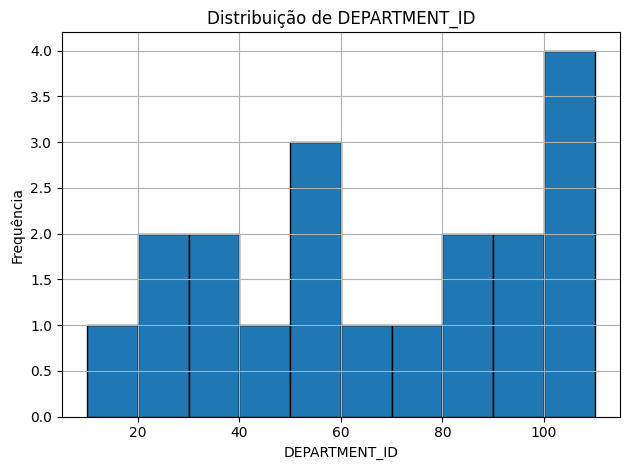

In [6]:
# 1. Importar as bibliotecas
import pandas as pd
import matplotlib.pyplot as plt

# 2. Carregar o arquivo CSV correto
# Alterado de 'query_01.csv' para 'query_1.csv', que é o arquivo de fato existente no ambiente.
nome_arquivo = "query_1.csv"

try:
    # Se o arquivo for separado por vírgula clássica (gerado pelo pandas.to_csv), use sep=","
    df = pd.read_csv(nome_arquivo, sep=",")
except FileNotFoundError:
    # Caso você queira testar com outro arquivo, mude o nome_arquivo acima
    print(f"Erro: O arquivo '{nome_arquivo}' não foi encontrado.")
    print("Por favor, verifique se o arquivo foi carregado ou se o nome está correto.")
    df = None

if df is not None:
    # 3. Inspeção inicial
    print("Primeiras linhas:")
    display(df.head())

    print("Dimensões (linhas, colunas):", df.shape)
    print("\nNomes das colunas:")
    print(df.columns.tolist())

    print("\nTipos de dados e valores preenchidos:")
    df.info()

    # 4. Verificar dados ausentes e linhas duplicadas
    print("\nValores ausentes por coluna:")
    print(df.isna().sum())

    print("\nLinhas duplicadas:", df.duplicated().sum())

    # 5. Estatísticas descritivas das colunas numéricas
    colunas_numericas = df.select_dtypes(include="number").columns

    if len(colunas_numericas) > 0:
        estatisticas = df[colunas_numericas].agg(
            ["mean", "median", "min", "max"]
        ).T

        estatisticas.columns = ["Média", "Mediana", "Mínimo", "Máximo"]
        print("\nEstatísticas básicas:")
        display(estatisticas)

        # Resumo adicional: contagem, desvio padrão e quartis
        print("\nResumo estatístico:")
        display(df[colunas_numericas].describe())

        # 6. Histograma da primeira coluna numérica
        coluna = colunas_numericas[0]
        df[coluna].dropna().hist(bins=10, edgecolor="black")

        plt.title(f"Distribuição de {coluna}")
        plt.xlabel(coluna)
        plt.ylabel("Frequência")
        plt.tight_layout()
        plt.show()
    else:
        print("Não foram encontradas colunas numéricas para calcular estatísticas ou criar o histograma.")

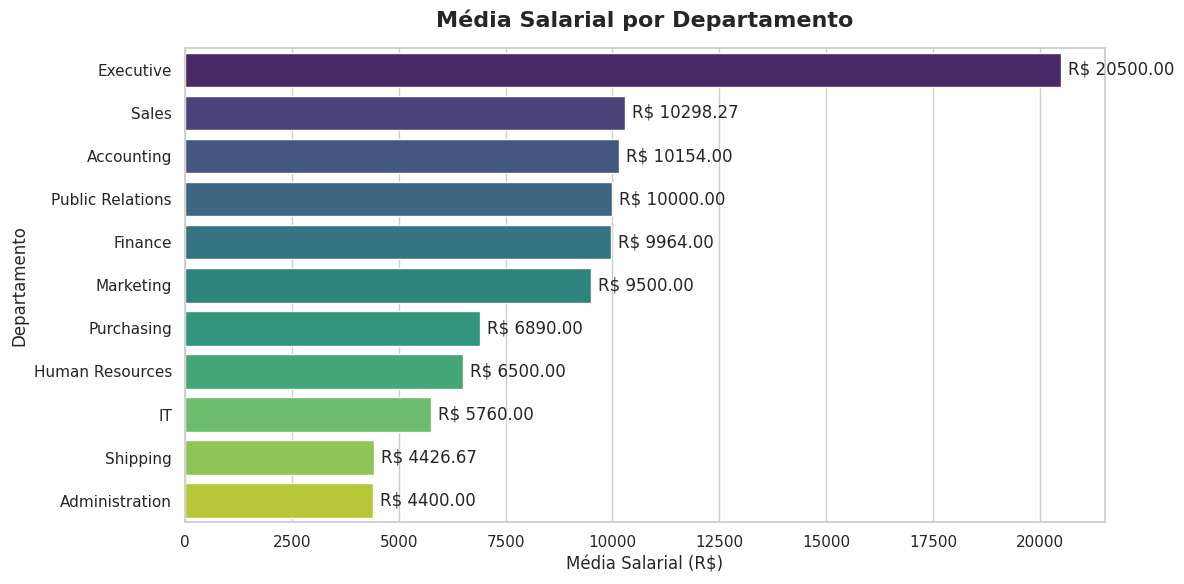

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Agrupar por departamento e calcular a média salarial
df_depto_salario = df.groupby('DEPARTMENT_NAME')['SALARIO_MEDIO'].mean().reset_index()

# Ordenar os valores para uma melhor visualização
df_depto_salario = df_depto_salario.sort_values(by='SALARIO_MEDIO', ascending=False)

# Configurar o tamanho da figura
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Criar o gráfico de barras
ax = sns.barplot(
    x='SALARIO_MEDIO',
    y='DEPARTMENT_NAME',
    data=df_depto_salario,
    palette='viridis',
    hue='DEPARTMENT_NAME',
    legend=False
)

# Adicionar os valores monetários formatados no final de cada barra
for i in ax.containers:
    ax.bar_label(i, fmt='R$ %.2f', padding=5)

# Ajustar títulos e rótulos
plt.title('Média Salarial por Departamento', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Média Salarial (R$)', fontsize=12)
plt.ylabel('Departamento', fontsize=12)

# Exibir o gráfico
plt.tight_layout()
plt.show()

### Análise de Correlação: Total de Funcionários vs. Salário Médio
Nesta seção, investigamos se existe alguma relação linear entre o número de funcionários de uma função/departamento (`TOTAL_FUNCIONARIOS`) e a respectiva remuneração média (`SALARIO_MEDIO`).

In [11]:
# Calcular a correlação de Pearson
correlacao = df['TOTAL_FUNCIONARIOS'].corr(df['SALARIO_MEDIO'])
print(f"Coeficiente de Correlação de Pearson: {correlacao:.4f}")

if abs(correlacao) < 0.3:
    interpretacao = "Correlação fraca ou quase nula."
elif abs(correlacao) < 0.7:
    interpretacao = "Correlação moderada."
else:
    interpretacao = "Correlação forte."

print(f"Interpretação: {interpretacao}")

Coeficiente de Correlação de Pearson: -0.3583
Interpretação: Correlação moderada.


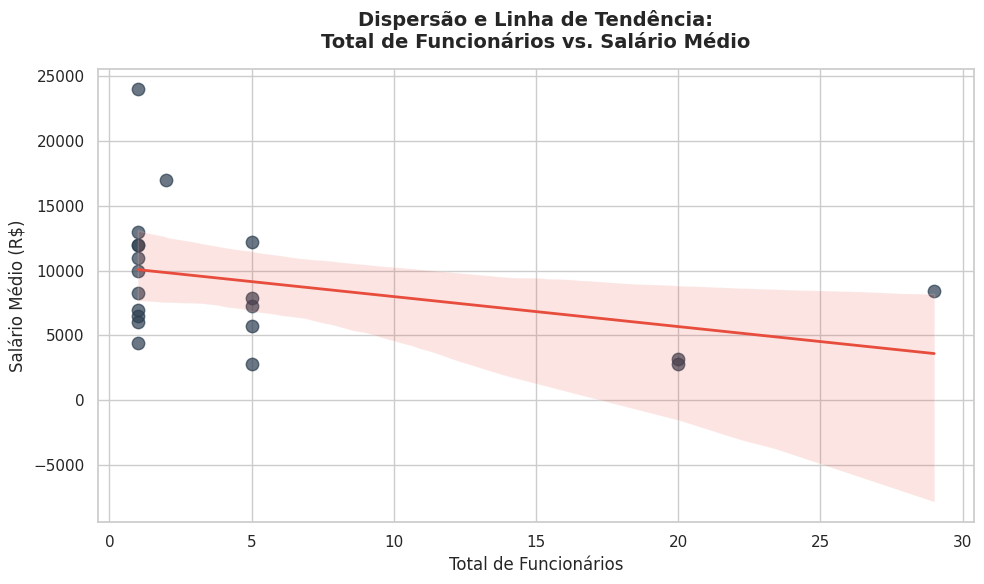

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo do gráfico
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Gráfico de dispersão com linha de regressão
sns.regplot(
    x='TOTAL_FUNCIONARIOS',
    y='SALARIO_MEDIO',
    data=df,
    scatter_kws={'s': 80, 'alpha': 0.7, 'color': '#2c3e50'},
    line_kws={'color': '#e74c3c', 'linewidth': 2}
)

# Títulos e rótulos
plt.title('Dispersão e Linha de Tendência:\nTotal de Funcionários vs. Salário Médio', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Total de Funcionários', fontsize=12)
plt.ylabel('Salário Médio (R$)', fontsize=12)

# Exibir gráfico
plt.tight_layout()
plt.show()